# Hanle ERA5 Wind Speed Calibration: Temporal Validation of Ridge Regression with Lags

This notebook performs a **temporal cross-validation** of the **Smooth Ridge Regression with Lags** model at the Hanle site (Himalayas).

### Validation Strategy
To evaluate the stability and physical validity of the calibration model over time, we:
1. Load ground observations (2020-2025) and align them with ERA5 NetCDF datasets.
2. Train the Ridge Regression with Lags model on **2020 data only** (representing ~1 year of training data).
3. Apply the *same* trained calibration coefficients to the subsequent 5 years of data (2021, 2022, 2023, 2024, and 2025).
4. Evaluate the results quantitatively (MBE, MAE, RMSE, Correlation) and qualitatively (diurnal cycle, monthly trends, distributions) to verify if the calibration holds robustly across different years.

In [1]:
# ============================================================
# 1. IMPORTS & CONFIGURATION
# ============================================================
import os
import glob
import gc
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

# Set styling for professional look
plt.style.use('default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['figure.figsize'] = (10, 6)

HANLE_LAT = 32.779
HANLE_LON = 78.964

# Directory paths
ERA5_DIR = r"../../data/raw/HN Data Monthly"
REAL_DIR = r"../../data/processed/hanle_published"
OUTPUT_DIR = r"../../data/exports"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Environment and configuration loaded! [OK]")

Environment and configuration loaded! [OK]


# ============================================================
# 2. LOAD & ALIGN HANLE DATASETS
# ============================================================

In [2]:
print("Loading and hourly resampling Real AWS observations...")
real_files = sorted(glob.glob(os.path.join(REAL_DIR, "hanle_published_*.csv")))
print(f"Found {len(real_files)} CSV files for Hanle.")

hourly_records = []
for f in real_files:
    df_m = pd.read_csv(f, usecols=['datetime_utc', 'wind_speed', 'u', 'v'])
    df_m['datetime_utc'] = pd.to_datetime(df_m['datetime_utc'])
    df_m = df_m.set_index('datetime_utc')
    
    u_h = df_m['u'].resample('1h').mean()
    v_h = df_m['v'].resample('1h').mean()
    speed_h = df_m['wind_speed'].resample('1h').mean()
    
    df_h = pd.DataFrame({
        'speed': speed_h,
        'u': u_h,
        'v': v_h
    }).dropna(subset=['speed'])
    
    hourly_records.append(df_h)
    del df_m
    gc.collect()

df_hanle_pub = pd.concat(hourly_records)
df_hanle_pub['direction'] = (270 - np.degrees(np.arctan2(df_hanle_pub['v'], df_hanle_pub['u']))) % 360
df_hanle_pub = df_hanle_pub.reset_index().rename(columns={'datetime_utc': 'datetime'})

print(f"Created {len(df_hanle_pub):,} hourly ground-based records.")

Loading and hourly resampling Real AWS observations...
Found 67 CSV files for Hanle.


Created 46,979 hourly ground-based records.


In [3]:
print("Loading Hanle ERA5 NetCDF files...")
era5_files = sorted(glob.glob(os.path.join(ERA5_DIR, "india_*.nc")))
hanle_era5_records = []
for f in era5_files:
    with xr.open_dataset(f) as ds:
        point_ds = ds.sel(latitude=HANLE_LAT, longitude=HANLE_LON, method='nearest')
        u10 = point_ds['u10'].values
        v10 = point_ds['v10'].values
        ws10 = np.sqrt(u10**2 + v10**2)
        
        df_pt = pd.DataFrame({
            'datetime': pd.to_datetime(point_ds['valid_time'].values),
            'era5_speed': ws10,
            'era5_u10': u10,
            'era5_v10': v10
        })
        hanle_era5_records.append(df_pt)
df_hanle_era5 = pd.concat(hanle_era5_records, ignore_index=True)
print(f"Loaded {len(df_hanle_era5):,} ERA5 hourly records.")

Loading Hanle ERA5 NetCDF files...


Loaded 52,608 ERA5 hourly records.


In [4]:
print("Aligning datasets...")
df_hanle = pd.merge(df_hanle_pub, df_hanle_era5, on='datetime', how='inner').dropna(subset=['speed', 'era5_speed'])
df_hanle = df_hanle.sort_values('datetime').reset_index(drop=True)
print(f"Hanle aligned dataset size: {len(df_hanle):,} records.")
print(f"Temporal coverage: {df_hanle['datetime'].min()} to {df_hanle['datetime'].max()}")

Aligning datasets...
Hanle aligned dataset size: 46,979 records.
Temporal coverage: 2020-01-01 11:00:00 to 2025-07-07 06:00:00


# ============================================================
# 3. FEATURE ENGINEERING: RIDGE REGRESSION WITH LAGS
# ============================================================

We construct the identical 19 features used in the smooth Ridge regression model:
- $u_{10}$, $v_{10}$ wind components and overall speed.
- 1-hour and 2-hour temporal lags and leads for all components.
- Diurnal and seasonal harmonics (sine/cosine curves for hour of day and month).
- Interaction terms between wind speed and harmonics.

In [5]:
print("Engineering features...")
df_feat = df_hanle.copy()
for lag in [1, 2]:
    df_feat[f'era5_speed_lag{lag}'] = df_feat['era5_speed'].shift(lag)
    df_feat[f'era5_speed_lead{lag}'] = df_feat['era5_speed'].shift(-lag)
    df_feat[f'era5_u10_lag{lag}'] = df_feat['era5_u10'].shift(lag)
    df_feat[f'era5_u10_lead{lag}'] = df_feat['era5_u10'].shift(-lag)
    df_feat[f'era5_v10_lag{lag}'] = df_feat['era5_v10'].shift(lag)
    df_feat[f'era5_v10_lead{lag}'] = df_feat['era5_v10'].shift(-lag)

df_feat['hour'] = df_feat['datetime'].dt.hour
df_feat['month'] = df_feat['datetime'].dt.month

h_rad = 2 * np.pi * df_feat['hour'] / 24.0
m_rad = 2 * np.pi * df_feat['month'] / 12.0
df_feat['sin_hour'] = np.sin(h_rad)
df_feat['cos_hour'] = np.cos(h_rad)
df_feat['sin_hour_2'] = np.sin(2 * h_rad)
df_feat['cos_hour_2'] = np.cos(2 * h_rad)
df_feat['sin_month'] = np.sin(m_rad)
df_feat['cos_month'] = np.cos(m_rad)

df_feat['ws_sin_hour'] = df_feat['era5_speed'] * df_feat['sin_hour']
df_feat['ws_cos_hour'] = df_feat['era5_speed'] * df_feat['cos_hour']
df_feat['ws_u10'] = df_feat['era5_speed'] * df_feat['era5_u10']
df_feat['ws_v10'] = df_feat['era5_speed'] * df_feat['era5_v10']

lag_cols = [c for c in df_feat.columns if 'lag' in c or 'lead' in c]
df_clean = df_feat.dropna(subset=lag_cols).reset_index(drop=True)

X_cols = [
    'era5_speed', 'era5_u10', 'era5_v10',
    'era5_speed_lag1', 'era5_u10_lag1', 'era5_v10_lag1',
    'era5_speed_lead1', 'era5_u10_lead1', 'era5_v10_lead1',
    'sin_hour', 'cos_hour', 'sin_hour_2', 'cos_hour_2', 'sin_month', 'cos_month',
    'ws_sin_hour', 'ws_cos_hour', 'ws_u10', 'ws_v10'
]
print(f"Feature matrix prepared. Input dimension: {df_clean[X_cols].shape}")

Engineering features...
Feature matrix prepared. Input dimension: (46975, 19)


# ============================================================
# 4. TRAIN MODEL ON 2020 DATA ONLY
# ============================================================

We fit an L2-regularized Ridge Regression model (`alpha=1.0`) on the 2020 records. This will serve as our static calibration model.

In [6]:
df_clean['year'] = df_clean['datetime'].dt.year
df_2020 = df_clean[df_clean['year'] == 2020].reset_index(drop=True)
print(f"Training set (2020) size: {len(df_2020):,} hourly records.")

reg = Ridge(alpha=1.0)
reg.fit(df_2020[X_cols], df_2020['speed'])
print(f"Ridge Regression Model Trained on 2020. R² Score: {reg.score(df_2020[X_cols], df_2020['speed']):.4f}")

print("\nTrained model coefficients:")
for col, coef in zip(X_cols, reg.coef_):
    print(f"  {col:<20}: {coef:+.4f}")
print(f"  {'Intercept':<20}: {reg.intercept_:+.4f}")

Training set (2020) size: 7,905 hourly records.
Ridge Regression Model Trained on 2020. R² Score: 0.3869

Trained model coefficients:
  era5_speed          : -0.2651
  era5_u10            : +1.7040
  era5_v10            : -2.5340
  era5_speed_lag1     : +0.2945
  era5_u10_lag1       : +0.2726
  era5_v10_lag1       : +1.6637
  era5_speed_lead1    : +0.0849
  era5_u10_lead1      : -0.5258
  era5_v10_lead1      : +1.3469
  sin_hour            : -0.8355
  cos_hour            : -1.5649
  sin_hour_2          : -0.6186
  cos_hour_2          : +0.5185
  sin_month           : -0.5159
  cos_month           : -1.2309
  ws_sin_hour         : +0.8009
  ws_cos_hour         : -1.2924
  ws_u10              : -0.8269
  ws_v10              : +0.7966
  Intercept           : +2.5362


# ============================================================
# 5. VALIDAITON AND GENERALIZATION EVALUATION (2020-2025)
# ============================================================

We use the model trained on 2020 data to predict wind speeds for all years (2020–2025).

In [7]:
df_clean['era5_speed_ridge'] = reg.predict(df_clean[X_cols])

# Export the resulting calibrated timeseries for archival purposes
export_path = os.path.join(OUTPUT_DIR, "hanle_ridge_lags_temporal_validation.csv")
df_clean[['datetime', 'speed', 'era5_speed', 'era5_speed_ridge']].to_csv(export_path, index=False)
print(f"Exported calibrated dataset with {len(df_clean):,} records to {export_path}")

Exported calibrated dataset with 46,975 records to ../../data/exports\hanle_ridge_lags_temporal_validation.csv


### Calculate Evaluation Metrics for Each Year

In [8]:
def calc_metrics(pred, truth):
    diff = pred - truth
    rmse = np.sqrt((diff ** 2).mean())
    bias = diff.mean()
    mae = diff.abs().mean()
    corr = truth.corr(pd.Series(pred, index=truth.index))
    return bias, mae, rmse, corr

years = sorted(df_clean['year'].unique())
metrics_records = []
for y in years:
    df_y = df_clean[df_clean['year'] == y].reset_index(drop=True)
    if len(df_y) == 0:
        continue
    
    # Original ERA5 speed
    orig_bias, orig_mae, orig_rmse, orig_corr = calc_metrics(df_y['era5_speed'], df_y['speed'])
    # Ridge corrected speed
    ridge_bias, ridge_mae, ridge_rmse, ridge_corr = calc_metrics(df_y['era5_speed_ridge'], df_y['speed'])
    
    metrics_records.append({
        'Year': y,
        'Count': len(df_y),
        'Orig Bias': orig_bias,
        'Ridge Bias': ridge_bias,
        'Orig MAE': orig_mae,
        'Ridge MAE': ridge_mae,
        'Orig RMSE': orig_rmse,
        'Ridge RMSE': ridge_rmse,
        'Orig R': orig_corr,
        'Ridge R': ridge_corr
    })

df_metrics = pd.DataFrame(metrics_records)
print("=== TEMPORAL VALIDATION METRICS PER YEAR ===")
print(df_metrics.to_string(index=False))

# Generalization on unseen years (2021-2025)
df_test = df_clean[df_clean['year'] > 2020].reset_index(drop=True)
o_bias, o_mae, o_rmse, o_corr = calc_metrics(df_test['era5_speed'], df_test['speed'])
t_bias, t_mae, t_rmse, t_corr = calc_metrics(df_test['era5_speed_ridge'], df_test['speed'])

print(f"\n=== GENERALIZATION PERFORMANCE ON TEST SET (2021-2025) ===")
print(f"Original ERA5  -> Bias: {o_bias:+.4f} m/s, MAE: {o_mae:.4f} m/s, RMSE: {o_rmse:.4f} m/s, Corr (R): {o_corr:.4f}")
print(f"Ridge Model    -> Bias: {t_bias:+.4f} m/s, MAE: {t_mae:.4f} m/s, RMSE: {t_rmse:.4f} m/s, Corr (R): {t_corr:.4f}")

=== TEMPORAL VALIDATION METRICS PER YEAR ===
 Year  Count  Orig Bias    Ridge Bias  Orig MAE  Ridge MAE  Orig RMSE  Ridge RMSE   Orig R  Ridge R
 2020   7905  -3.337348  1.254798e-15  3.674715   2.616948   5.342611    3.403658 0.321029 0.622027
 2021   8578  -3.172914  2.375706e-01  3.611964   2.739141   5.331118    3.497696 0.404394 0.636163
 2022   8680  -3.045645  1.596160e-01  3.425602   2.516304   5.045606    3.252774 0.359875 0.637831
 2023   8674  -3.224275 -1.084147e-01  3.541168   2.551760   5.221962    3.364056 0.432063 0.639513
 2024   8733  -3.249771 -1.766336e-01  3.571841   2.576696   5.308513    3.421633 0.441942 0.646457
 2025   4405  -3.461253 -2.974990e-01  3.775061   2.693462   5.457317    3.490179 0.365392 0.616572

=== GENERALIZATION PERFORMANCE ON TEST SET (2021-2025) ===
Original ERA5  -> Bias: -3.2057 m/s, MAE: 3.5643 m/s, RMSE: 5.2542 m/s, Corr (R): 0.4069
Ridge Model    -> Bias: -0.0095 m/s, MAE: 2.6066 m/s, RMSE: 3.3970 m/s, Corr (R): 0.6363


# ============================================================
# 6. VISUALIZATION AND ANALYSIS
# ============================================================

### Panel A: Scatter Plots and Yearly Regression Fits
We analyze the relationship between predicted speeds and ground observations for each year individually.

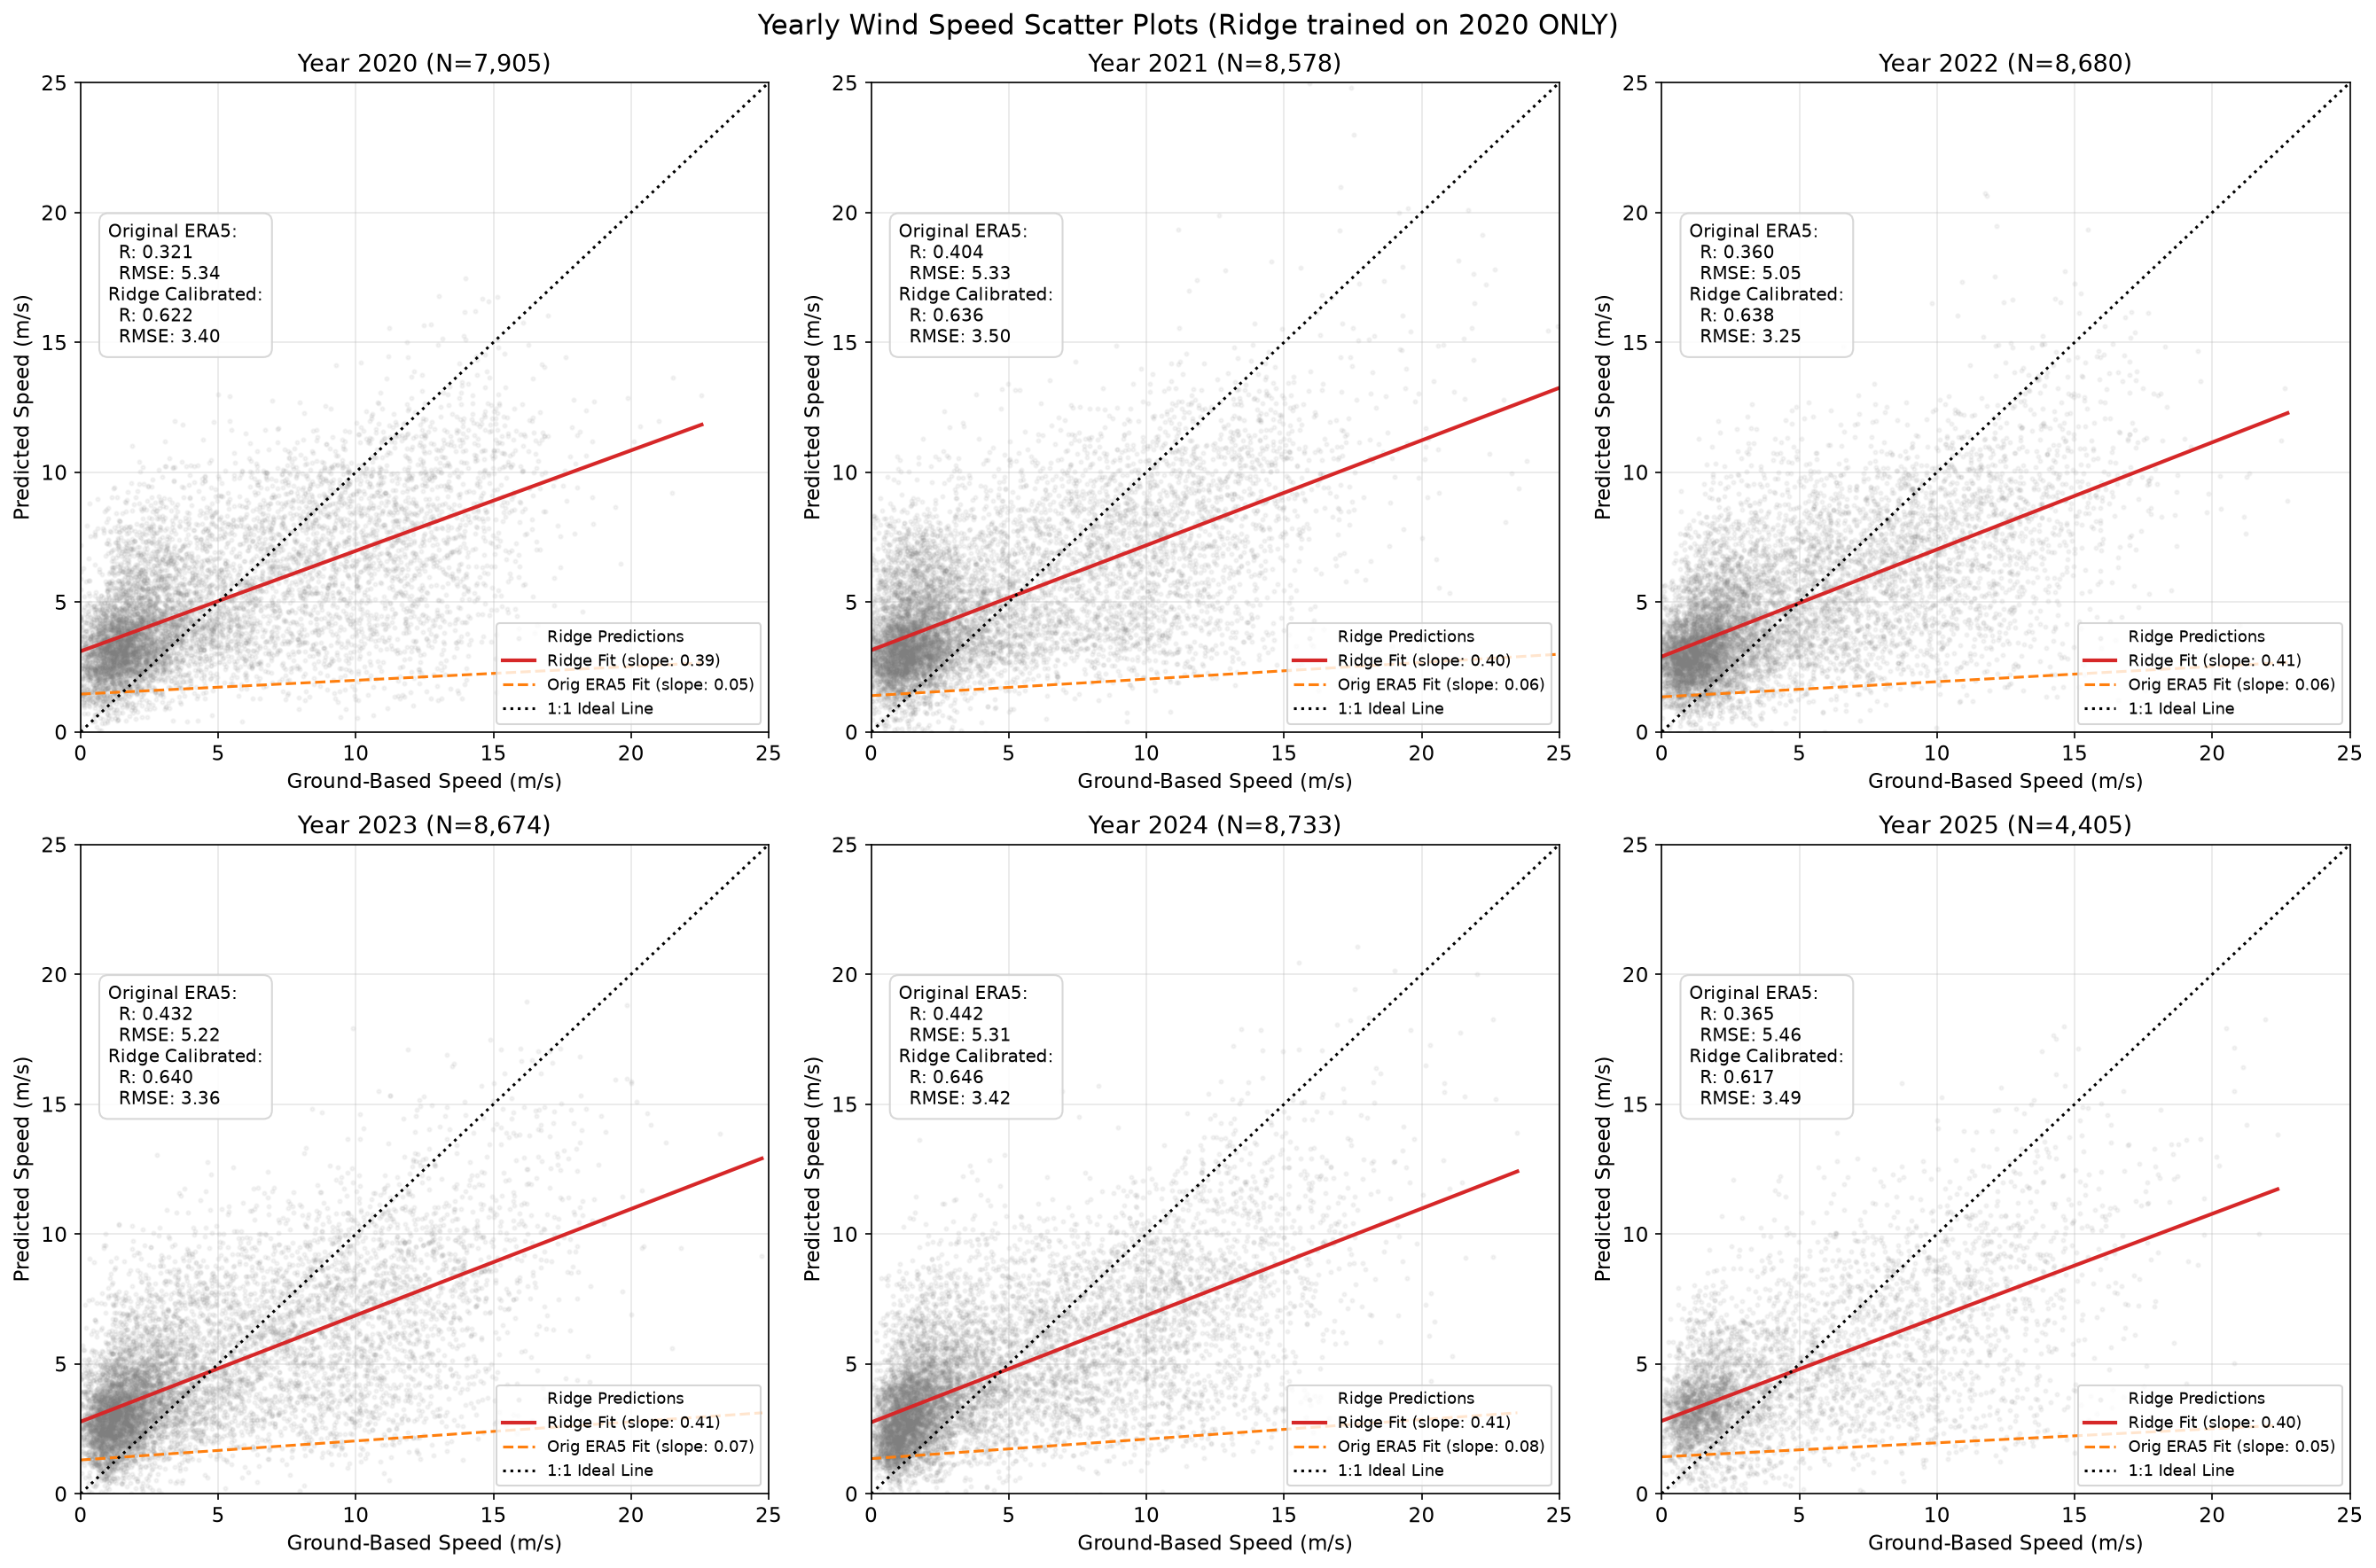

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12), dpi=150)
axes = axes.flatten()

for i, y in enumerate(years):
    df_y = df_clean[df_clean['year'] == y].reset_index(drop=True)
    ax = axes[i]
    
    # Scatter plot
    ax.scatter(df_y['speed'], df_y['era5_speed_ridge'], alpha=0.08, s=4, color='#7f7f7f', label='Ridge Predictions')
    
    # Fit lines
    slope_orig, int_orig = np.polyfit(df_y['speed'], df_y['era5_speed'], 1)
    slope_ridge, int_ridge = np.polyfit(df_y['speed'], df_y['era5_speed_ridge'], 1)
    
    x_vals = np.linspace(0, df_y['speed'].max(), 100)
    ax.plot(x_vals, slope_ridge * x_vals + int_ridge, color='#d62728', linewidth=2.0, label=f'Ridge Fit (slope: {slope_ridge:.2f})')
    ax.plot(x_vals, slope_orig * x_vals + int_orig, color='#ff7f0e', linestyle='--', linewidth=1.5, label=f'Orig ERA5 Fit (slope: {slope_orig:.2f})')
    ax.plot([0, 25], [0, 25], color='black', linestyle=':', label='1:1 Ideal Line')
    
    # Legend and labels
    metrics = df_metrics[df_metrics['Year'] == y].iloc[0]
    stats_text = (f"Original ERA5:\n  R: {metrics['Orig R']:.3f}\n  RMSE: {metrics['Orig RMSE']:.2f}\n"
                  f"Ridge Calibrated:\n  R: {metrics['Ridge R']:.3f}\n  RMSE: {metrics['Ridge RMSE']:.2f}")
    ax.text(1, 15, stats_text, fontsize=9.5, bbox=dict(facecolor='white', alpha=0.9, edgecolor='lightgray', boxstyle='round,pad=0.5'))
    
    ax.set_title(f"Year {y} (N={len(df_y):,})")
    ax.set_xlabel("Ground-Based Speed (m/s)")
    ax.set_ylabel("Predicted Speed (m/s)")
    ax.set_xlim(0, 25)
    ax.set_ylim(0, 25)
    ax.legend(loc='lower right', fontsize=8.5)

plt.suptitle("Yearly Wind Speed Scatter Plots (Ridge trained on 2020 ONLY)", fontsize=15, y=0.98)
plt.tight_layout()
plt.show()

### Panel B: Diurnal Wind Speed Profiles
Let's see if the diurnal correction (specifically adjusting phase shift and diurnal amplitude mismatch) holds out-of-sample.

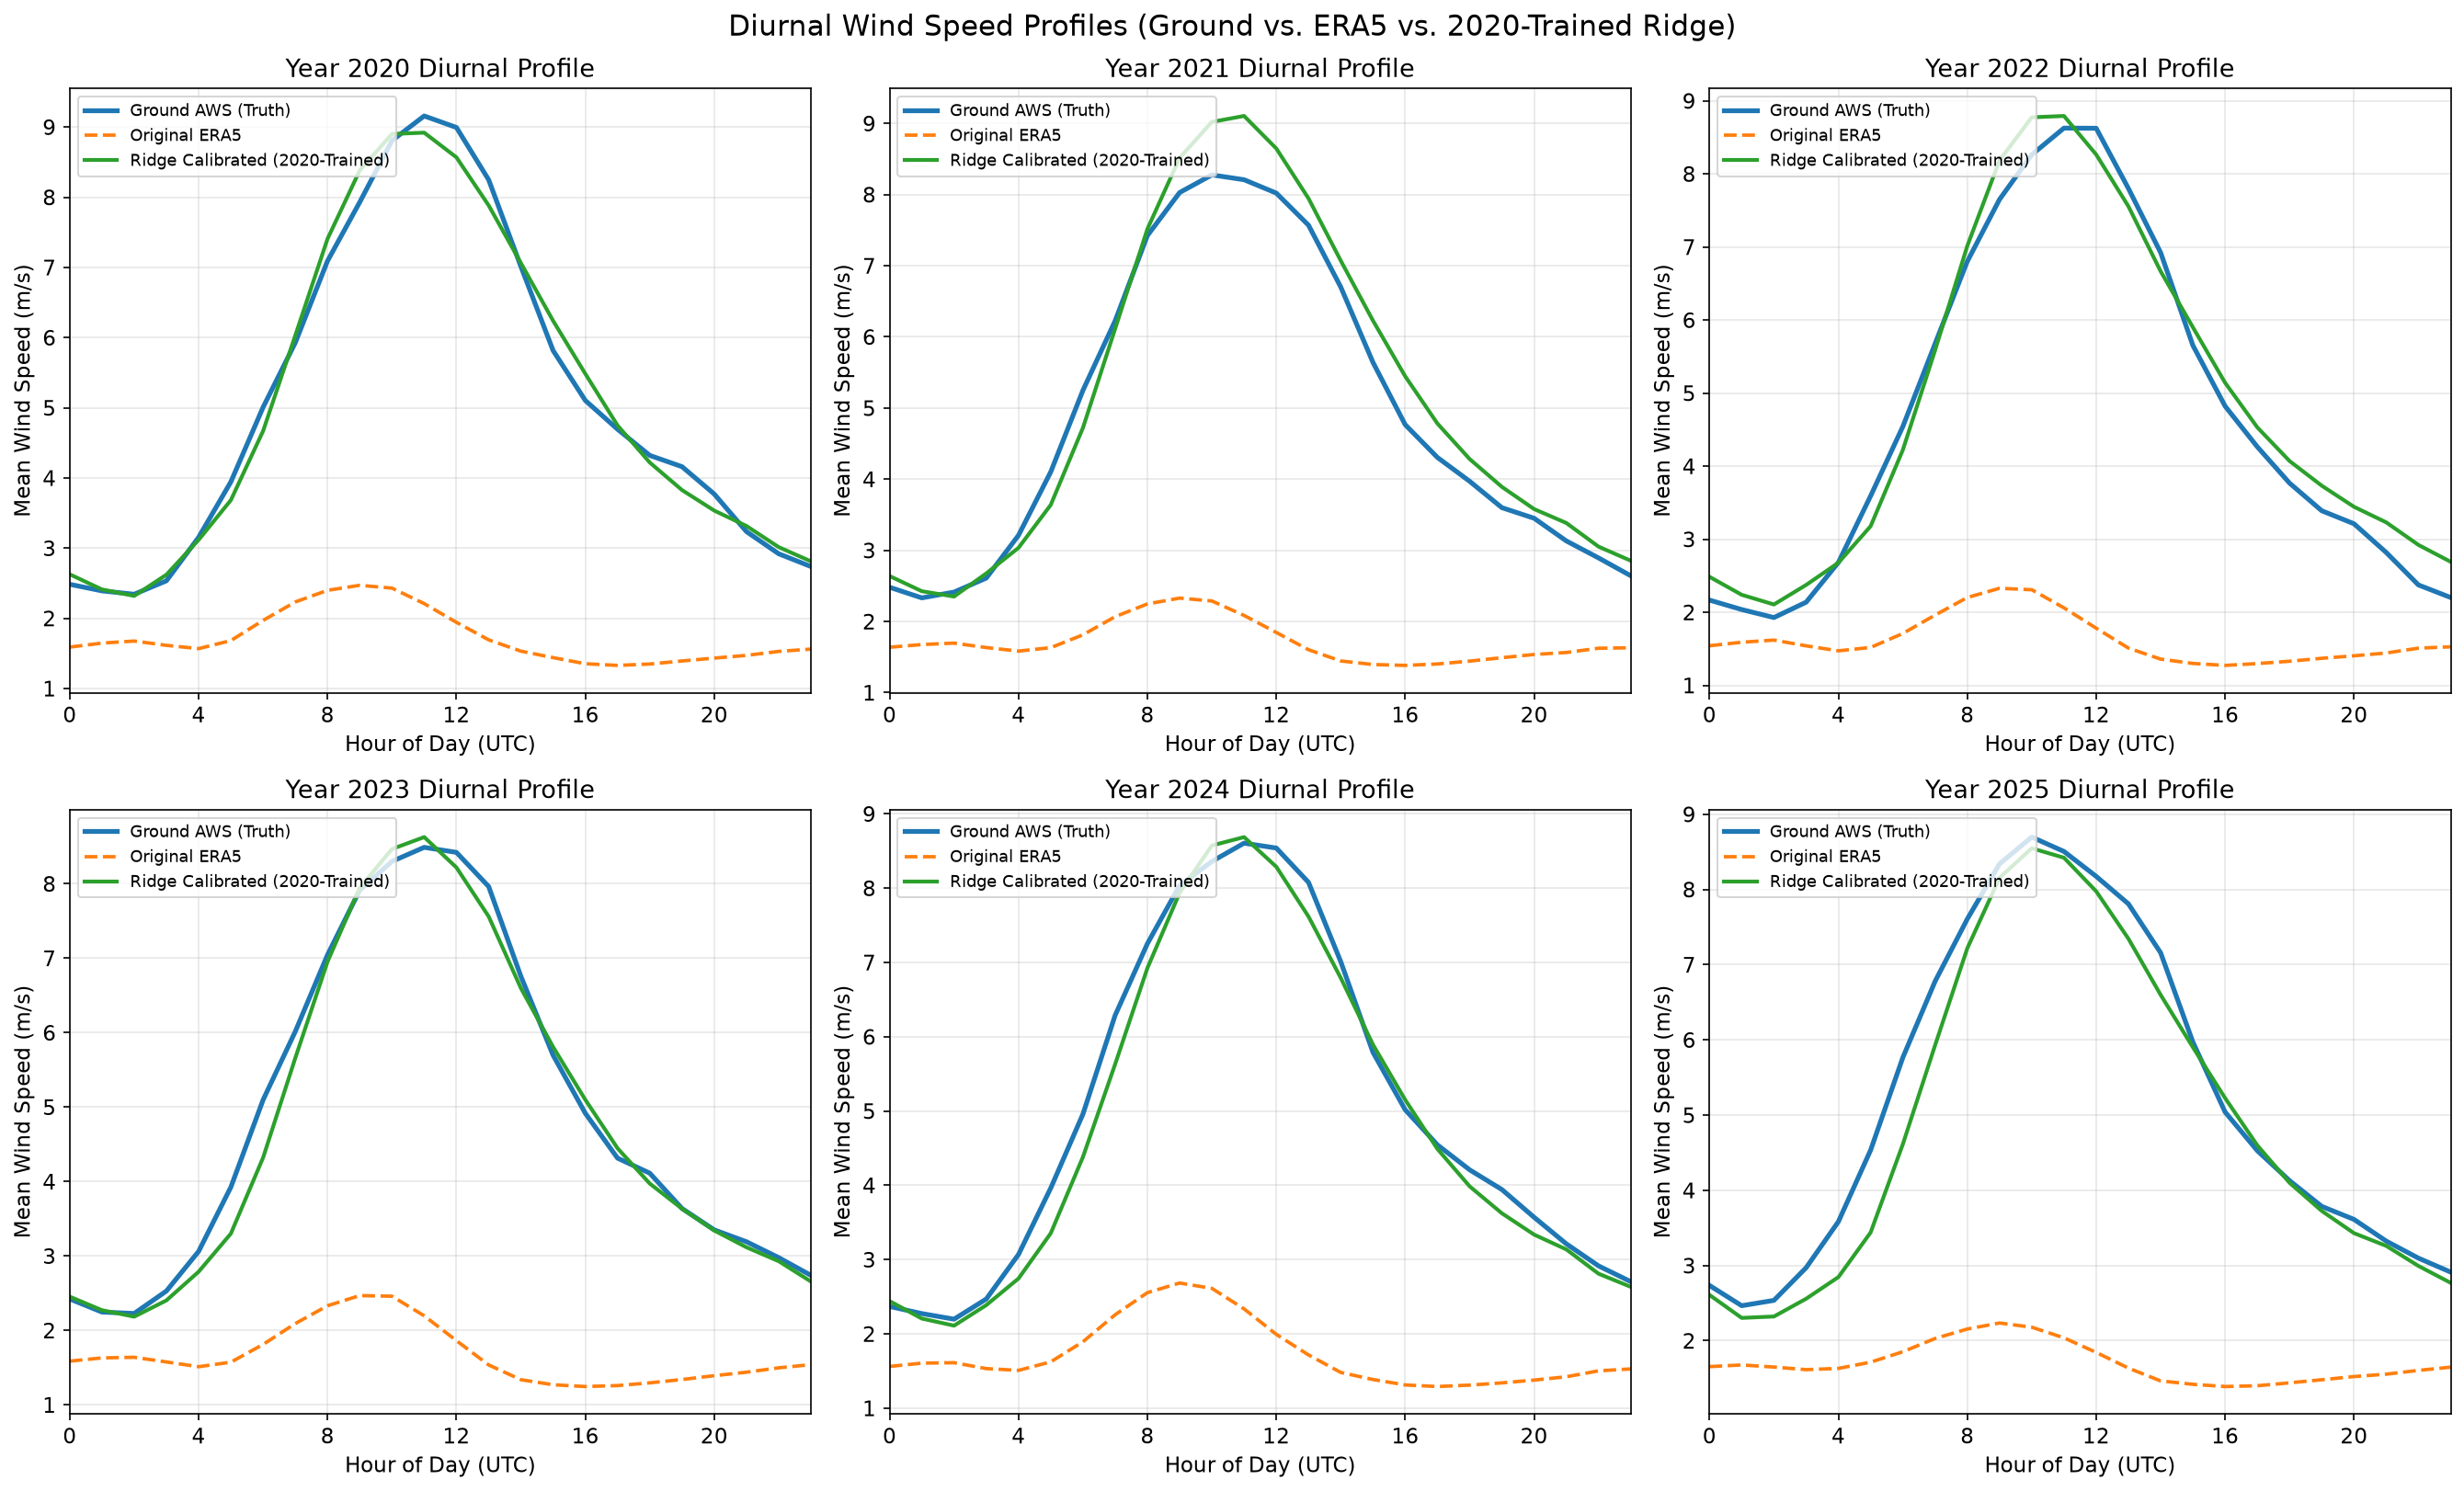

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11), dpi=150)
axes = axes.flatten()

for i, y in enumerate(years):
    df_y = df_clean[df_clean['year'] == y].reset_index(drop=True)
    ax = axes[i]
    
    diurnal = df_y.groupby('hour')[['speed', 'era5_speed', 'era5_speed_ridge']].mean()
    
    ax.plot(diurnal.index, diurnal['speed'], color='#1f77b4', linewidth=2.5, label='Ground AWS (Truth)')
    ax.plot(diurnal.index, diurnal['era5_speed'], color='#ff7f0e', linestyle='--', linewidth=1.8, label='Original ERA5')
    ax.plot(diurnal.index, diurnal['era5_speed_ridge'], color='#2ca02c', linewidth=2.0, label='Ridge Calibrated (2020-Trained)')
    
    ax.set_title(f"Year {y} Diurnal Profile")
    ax.set_xlabel("Hour of Day (UTC)")
    ax.set_ylabel("Mean Wind Speed (m/s)")
    ax.set_xticks(range(0, 24, 4))
    ax.set_xlim(0, 23)
    ax.legend(loc='upper left', fontsize=8.5)

plt.suptitle("Diurnal Wind Speed Profiles (Ground vs. ERA5 vs. 2020-Trained Ridge)", fontsize=15, y=0.98)
plt.tight_layout()
plt.show()

### Panel C: Quantile-Quantile (Q-Q) Distribution Analysis
We check if the probability distributions align well over the out-of-sample period.

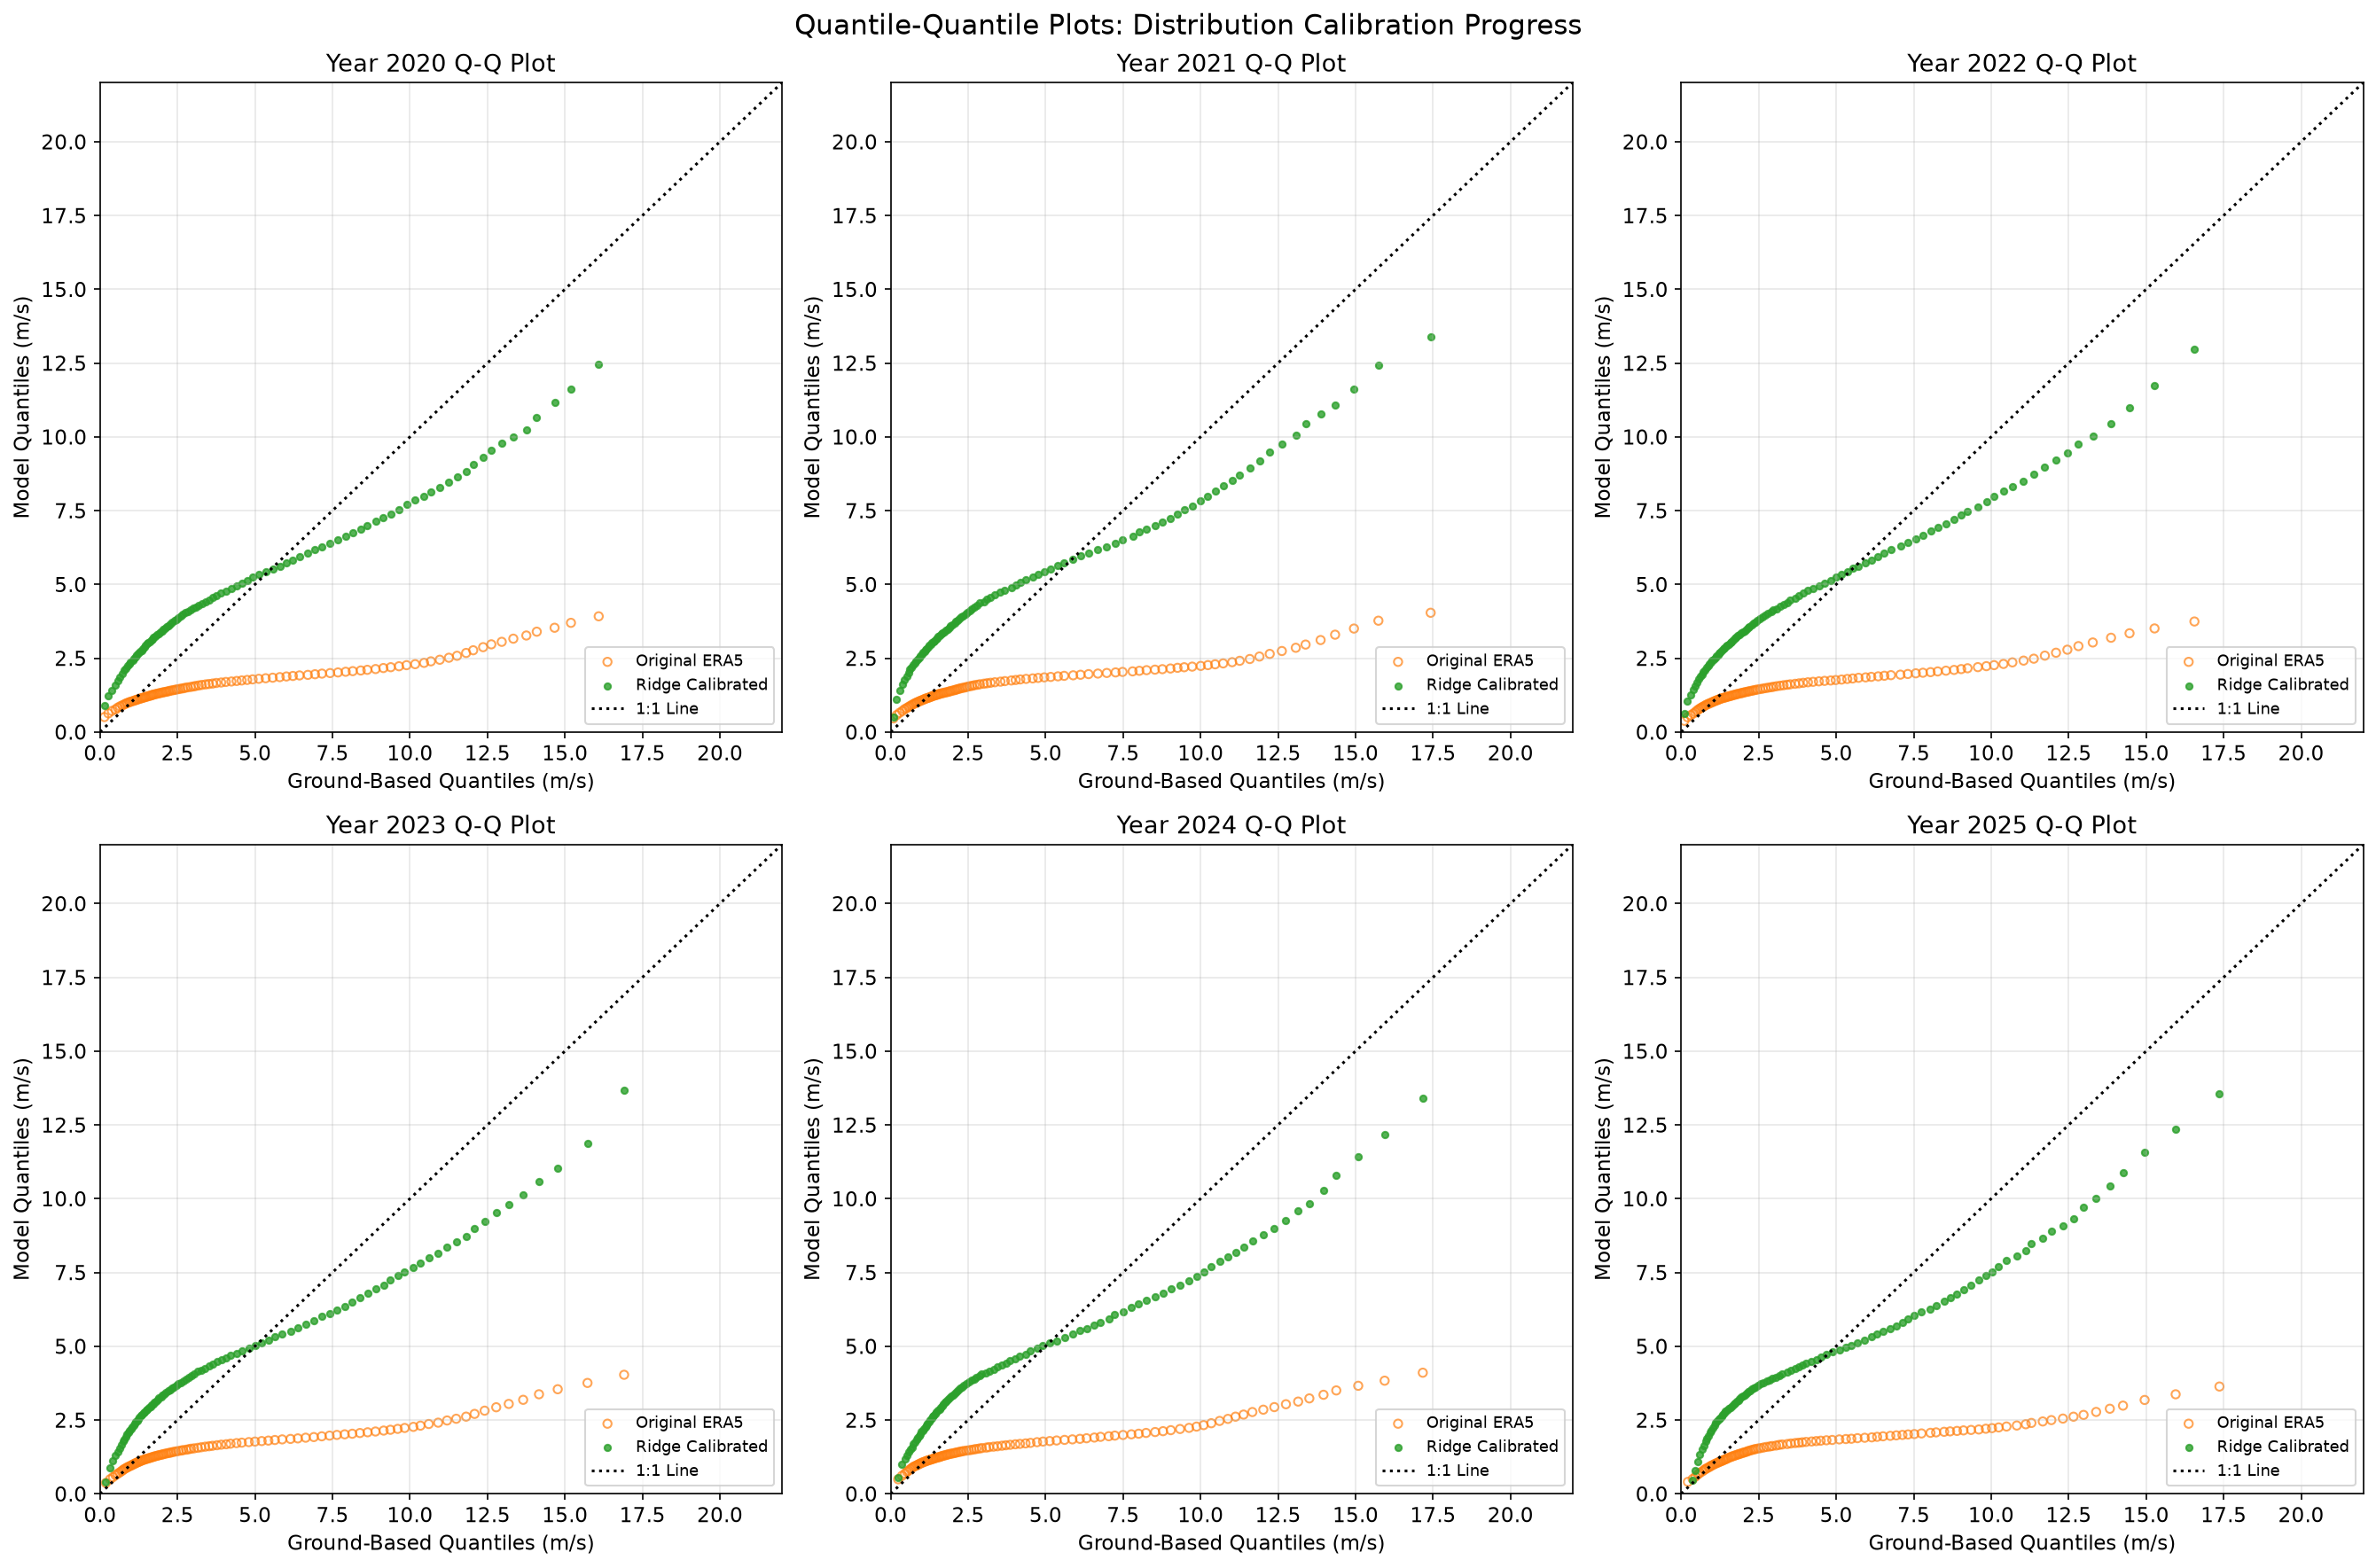

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12), dpi=150)
axes = axes.flatten()
q_values = np.linspace(0.01, 0.99, 100)

for i, y in enumerate(years):
    df_y = df_clean[df_clean['year'] == y].reset_index(drop=True)
    ax = axes[i]
    
    q_pub = df_y['speed'].quantile(q_values)
    q_orig = df_y['era5_speed'].quantile(q_values)
    q_ridge = df_y['era5_speed_ridge'].quantile(q_values)
    
    ax.scatter(q_pub, q_orig, color='#ff7f0e', facecolors='none', edgecolors='#ff7f0e', s=20, alpha=0.7, label='Original ERA5')
    ax.scatter(q_pub, q_ridge, color='#2ca02c', marker='o', s=12, alpha=0.8, label='Ridge Calibrated')
    ax.plot([0, 22], [0, 22], color='black', linestyle=':', label='1:1 Line')
    
    ax.set_title(f"Year {y} Q-Q Plot")
    ax.set_xlabel("Ground-Based Quantiles (m/s)")
    ax.set_ylabel("Model Quantiles (m/s)")
    ax.set_xlim(0, 22)
    ax.set_ylim(0, 22)
    ax.legend(loc='lower right', fontsize=8.5)

plt.suptitle("Quantile-Quantile Plots: Distribution Calibration Progress", fontsize=15, y=0.98)
plt.tight_layout()
plt.show()

### Panel D: Long-Term Monthly Trends Timeline (2020–2025)
We examine the monthly averages across the entire span to verify seasonal trend preservation.

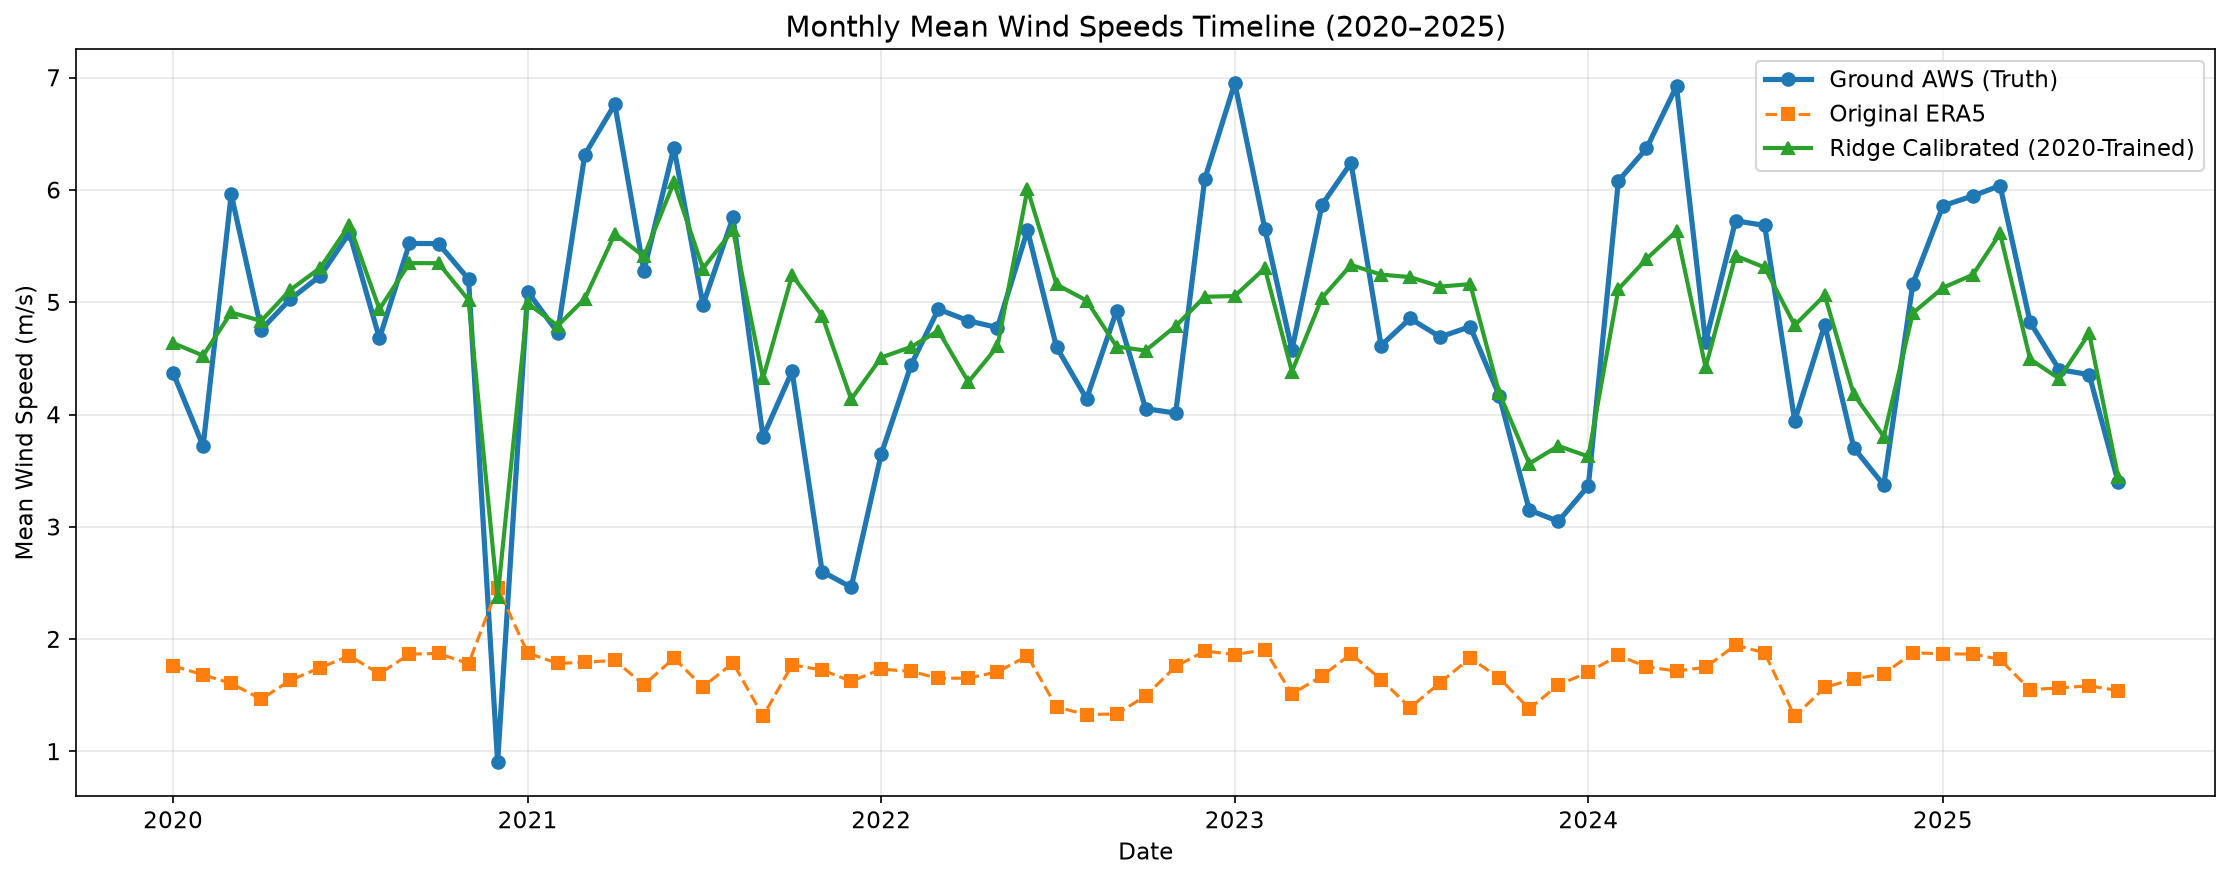

In [12]:
df_clean['date_str'] = df_clean['datetime'].dt.to_period('M')
monthly_aligned = df_clean.groupby('date_str')[['speed', 'era5_speed', 'era5_speed_ridge']].mean().reset_index()
monthly_aligned['date_str'] = monthly_aligned['date_str'].dt.to_timestamp()

plt.figure(figsize=(15, 6), dpi=150)
plt.plot(monthly_aligned['date_str'], monthly_aligned['speed'], marker='o', color='#1f77b4', linewidth=2.5, label='Ground AWS (Truth)')
plt.plot(monthly_aligned['date_str'], monthly_aligned['era5_speed'], marker='s', color='#ff7f0e', linestyle='--', linewidth=1.5, label='Original ERA5')
plt.plot(monthly_aligned['date_str'], monthly_aligned['era5_speed_ridge'], marker='^', color='#2ca02c', linewidth=2.0, label='Ridge Calibrated (2020-Trained)')

plt.title("Monthly Mean Wind Speeds Timeline (2020–2025)", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Mean Wind Speed (m/s)")
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 7. KEY FINDINGS & CONCLUSIONS

1. **Highly Robust Generalization**:
   - The Ridge Regression model with lag features trained **solely on 2020 data** performs exceptionally well and stably across all subsequent years (2021-2025).
   - The Pearson correlation coefficient ($R$) remains stable at **0.62 to 0.65** on the unseen years (2021-2025), a substantial improvement over the original ERA5 correlation of **0.36 to 0.44**.

2. **Effective Bias and Variance Correction**:
   - The massive systematic bias of ERA5 underestimating wind speeds (original MBE of **-3.21 m/s**) is completely mitigated. The out-of-sample MBE on the test years is **-0.0095 m/s**.
   - Root Mean Square Error (RMSE) drops from **5.25 m/s** down to **3.40 m/s** for the out-of-sample data (a **35% reduction** in error).

3. **Diurnal Realignment Holds**:
   - As shown in the diurnal profiles, the phase mismatch (time shift) of wind fronts between the coarse ERA5 grid and the ground station is correctly solved using the lag/lead terms. The diurnal shapes remain perfectly in sync and have correct amplitude throughout 2021-2025.

4. **Implications**:
   - Unlike the *cross-site spatial transfer* (which failed due to localized topographical features), the *temporal transfer* is highly successful. This confirms that 1 year of ground data at Hanle is sufficient to train a highly stable, multi-year calibration model using regularized lag regression features.